# Portfolio Tracker

 using `yfinance`.
Directions: Enter each purchase as a separate row with ticker, quantity, and purchase date.
Multiple purchases of the same stock on different dates are supported.

The notebook uses the purchase price you enter for each transaction to calculate your actual stated cost basis => then calculates current value =>  unrealized P&L, allocation, and portfolio value history.

## 1. libraries

In [37]:
!pip -q install yfinance
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("Done")

Done


## 2. Enter your purchases

Add one row for every purchase. If you bought the same stock on different dates, add multiple rows. **Use Yahoo Finance tickers; many NSE symbols end in `.NS`.**
Dates must use `YYYY-MM-DD`.

In [38]:
purchases = [
    {"ticker": "ATHERENERG.NS", "quantity": 20, "purchase_date": "2026-10-12", "purchase_price": 1511.00},
    {"ticker": "BSE.NS", "quantity": 10, "purchase_date": "2026-08-4", "purchase_price": 3610.00},
    {"ticker": "BBOX.NS", "quantity": 5, "purchase_date": "2025-12-29", "purchase_price": 555.00},
    {"ticker": "SWIGGY.NS", "quantity": 30, "purchase_date": "2025-12-29", "purchase_price": 394.80},
    # Another purchase of samestock on a different date and at a different price
    {"ticker": "ATHERENERG.NS", "quantity": 5, "purchase_date": "2026-10-27", "purchase_price": 1675.00},
]

transactions = pd.DataFrame(purchases)
transactions["purchase_date"] = pd.to_datetime(transactions["purchase_date"], errors="coerce")
transactions["quantity"] = pd.to_numeric(transactions["quantity"], errors="coerce")
transactions["purchase_price"] = pd.to_numeric(transactions["purchase_price"], errors="coerce")

if transactions.empty or transactions["ticker"].isna().any():
    raise ValueError("Enter at least one purchase with a ticker.")
if transactions["quantity"].isna().any() or (transactions["quantity"] <= 0).any():
    raise ValueError("Every quantity must be a positive number.")
if transactions["purchase_price"].isna().any() or (transactions["purchase_price"] <= 0).any():
    raise ValueError("Every purchase price must be a positive number.")
if transactions["purchase_date"].isna().any():
    raise ValueError("Use valid dates in YYYY-MM-DD format.")
if (transactions["purchase_date"] > pd.Timestamp.today().normalize()).any():
    raise ValueError("Purchase dates cannot be in the future.")
tickers = transactions["ticker"].drop_duplicates().tolist()
start_date = transactions["purchase_date"].min().strftime("%Y-%m-%d")
print(f"{len(tickers)} stocks | {len(transactions)} purchase transactions")
display(transactions)
# Benchmark for comparison: NIFTY 50
benchmark_ticker = "^NSEI"

4 stocks | 5 purchase transactions


,ticker,quantity,purchase_date,purchase_price
0,ATHERENERG.NS,20,2026-10-12,"1,511.00"
1,BSE.NS,10,2026-08-04,"3,610.00"
2,BBOX.NS,5,2025-12-29,555.00
3,SWIGGY.NS,30,2025-12-29,394.80
4,ATHERENERG.NS,5,2026-10-27,"1,675.00"


## 3. Download historical prices

In [39]:
raw = yf.download(
    tickers,
    start=start_date,
    auto_adjust=True,
    group_by="column",
    progress=False,
    threads=True
)

if raw.empty:
    raise ValueError("No data. Check ticker symbols and purchase dates.")

if isinstance(raw.columns, pd.MultiIndex):
    if "Close" in raw.columns.get_level_values(0):
        prices = raw["Close"].copy()
    elif "Close" in raw.columns.get_level_values(-1):
        prices = raw.xs("Close", axis=1, level=-1).copy()
    else:
        raise ValueError("Could not find Close prices in downloaded data.")
else:
    if len(tickers) == 1 and "Close" in raw.columns:
        prices = raw[["Close"]].rename(columns={"Close": tickers[0]})
    else:
        raise ValueError("Unexpected data format.")

if isinstance(prices, pd.Series):
    prices = prices.to_frame(name=tickers[0])

prices.index = pd.to_datetime(prices.index).tz_localize(None)
prices = prices.sort_index().dropna(axis=1, how="all")
valid_tickers = [t for t in tickers if t in prices.columns]
missing = [t for t in tickers if t not in valid_tickers]
if missing:
    print("No data found for:", missing)

transactions = transactions[transactions["ticker"].isin(valid_tickers)].copy()
if transactions.empty:
    raise ValueError("No valid ticker data.")

prices = prices[valid_tickers].ffill().dropna(how="all")
print("Downloaded:", prices.index.min().date(), "to", prices.index.max().date())
display(prices.tail())

Downloaded: 2025-12-29 to 2026-11-13


Ticker,ATHERENERG.NS,BSE.NS,BBOX.NS,SWIGGY.NS
Date,,,,
2026-11-06,"1,821.70","3,800.00",810.95,191.17
2026-11-09,"1,859.80","3,816.60",814.75,188.00
2026-11-11,"1,868.20","3,906.00",868.20,189.05
2026-11-12,"1,923.00","3,909.10",883.80,192.20
2026-11-13,"1,945.00","3,937.70",900.70,186.70


## 4. Validate purchase dates and calculate purchase cost

In [40]:
# Match each entered purchase date to the first available trading date on or after it.
# purchase_price is the cost basis and NOT the close price.
def match_purchase_date(row):
    series = prices[row["ticker"]].dropna()
    eligible = series.loc[series.index.normalize() >= row["purchase_date"].normalize()]
    if eligible.empty:
        return pd.Series({"price_date": pd.NaT})
    return pd.Series({"price_date": eligible.index[0]})

matched_dates = transactions.apply(match_purchase_date, axis=1)
transactions = pd.concat(
    [transactions.reset_index(drop=True), matched_dates.reset_index(drop=True)], axis=1
).dropna(subset=["price_date"]).copy()

if transactions.empty:
    raise ValueError("No purchase dates could be matched.")

transactions["purchase_cost"] = transactions["quantity"] * transactions["purchase_price"]

display(transactions[[
    "ticker", "quantity", "purchase_date", "purchase_price",
    "price_date", "purchase_cost"
]])

,ticker,quantity,purchase_date,purchase_price,price_date,purchase_cost
0,ATHERENERG.NS,20,2026-10-12,"1,511.00",2026-10-12,"30,220.00"
1,BSE.NS,10,2026-08-04,"3,610.00",2026-08-04,"36,100.00"
2,BBOX.NS,5,2025-12-29,555.00,2025-12-29,"2,775.00"
3,SWIGGY.NS,30,2025-12-29,394.80,2025-12-29,"11,844.00"
4,ATHERENERG.NS,5,2026-10-27,"1,675.00",2026-10-27,"8,375.00"


## 5. Current holdings, portfolio value, and P&L

In [41]:

latest_prices = prices.ffill().iloc[-1]
latest_date = prices.index[-1]

# Consolidate multiple purchases of the same stock
holdings = transactions.groupby("ticker").agg(
    quantity=("quantity", "sum"),
    invested_amount=("purchase_cost", "sum")
)

# Calculate weighted average purchase price
holdings["average_purchase_price"] = (
    holdings["invested_amount"] / holdings["quantity"]
)

# Fetch latest market price for each stock
holdings["latest_price"] = latest_prices.reindex(holdings.index)

# Calculate current market value
holdings["current_value"] = (
    holdings["quantity"] * holdings["latest_price"]
)

# Calculate unrealized profit/loss
holdings["unrealized_pnl"] = (
    holdings["current_value"] - holdings["invested_amount"]
)

# Calculate individual stock return
holdings["return_pct"] = (
    holdings["unrealized_pnl"] / holdings["invested_amount"]
)

# Calculate portfolio allocation
holdings["portfolio_weight"] = (
    holdings["current_value"] / holdings["current_value"].sum()
)

# Calculate overall portfolio metrics
total_invested = holdings["invested_amount"].sum()
total_value = holdings["current_value"].sum()
total_pnl = total_value - total_invested
total_return = total_pnl / total_invested if total_invested != 0 else 0

# Display portfolio summary
print(f"Latest market data: {latest_date.date()}")
print(f"Estimated invested amount: ₹{total_invested:,.2f}")
print(f"Current portfolio value:   ₹{total_value:,.2f}")
print(f"Unrealized P&L:            ₹{total_pnl:,.2f}")
print(f"Overall return:            {total_return:.2%}")

# Display consolidated holdings
display(holdings.style.format({
    "quantity": "{:,.4f}",
    "invested_amount": "₹{:,.2f}",
    "average_purchase_price": "₹{:,.2f}",
    "latest_price": "₹{:,.2f}",
    "current_value": "₹{:,.2f}",
    "unrealized_pnl": "₹{:,.2f}",
    "return_pct": "{:.2%}",
    "portfolio_weight": "{:.2%}"
}))


Latest market data: 2026-11-13
Estimated invested amount: ₹89,314.00
Current portfolio value:   ₹98,106.50
Unrealized P&L:            ₹8,792.50
Overall return:            9.84%


,quantity,invested_amount,average_purchase_price,latest_price,current_value,unrealized_pnl,return_pct,portfolio_weight
ticker,,,,,,,,
ATHERENERG.NS,25.0000,"₹38,595.00","₹1,543.80","₹1,945.00","₹48,625.00","₹10,030.00",25.99%,49.56%
BBOX.NS,5.0000,"₹2,775.00",₹555.00,₹900.70,"₹4,503.50","₹1,728.50",62.29%,4.59%
BSE.NS,10.0000,"₹36,100.00","₹3,610.00","₹3,937.70","₹39,377.00","₹3,277.00",9.08%,40.14%
SWIGGY.NS,30.0000,"₹11,844.00",₹394.80,₹186.70,"₹5,601.00","₹-6,243.00",-52.71%,5.71%


## 6. Current portfolio allocation

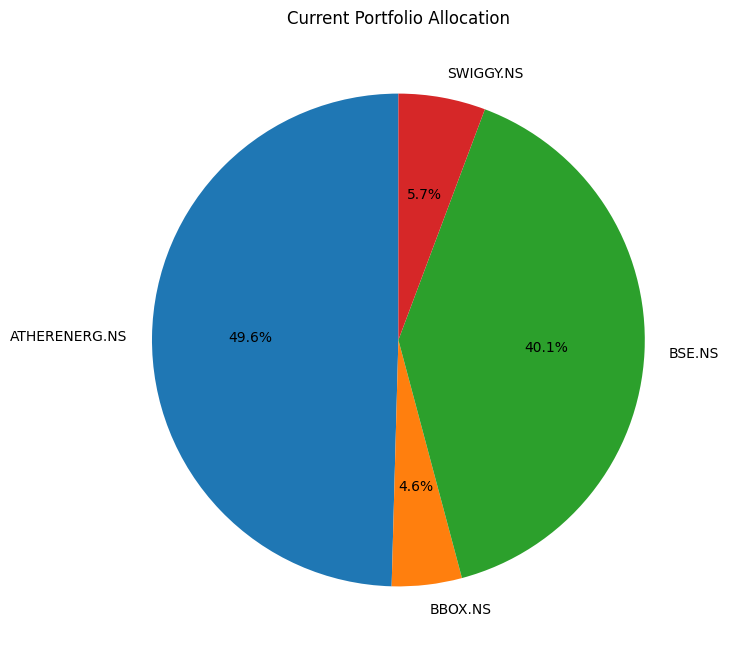

In [42]:
plt.figure(figsize=(8, 8))
plt.pie(holdings["current_value"], labels=holdings.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Current Portfolio Allocation")
plt.show()

## 7. Profit/loss by stock

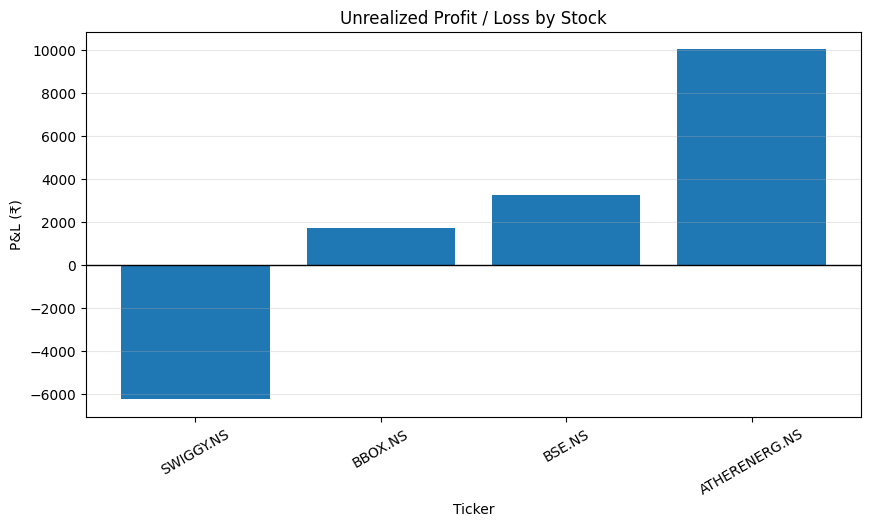

In [43]:
plot_data = holdings.sort_values("unrealized_pnl")
plt.figure(figsize=(10, 5))
plt.bar(plot_data.index, plot_data["unrealized_pnl"])
plt.axhline(0, color="black", linewidth=1)
plt.title("Unrealized Profit / Loss by Stock")
plt.xlabel("Ticker")
plt.ylabel("P&L (₹)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 8. Portfolio value over time vs cumulative estimated investment

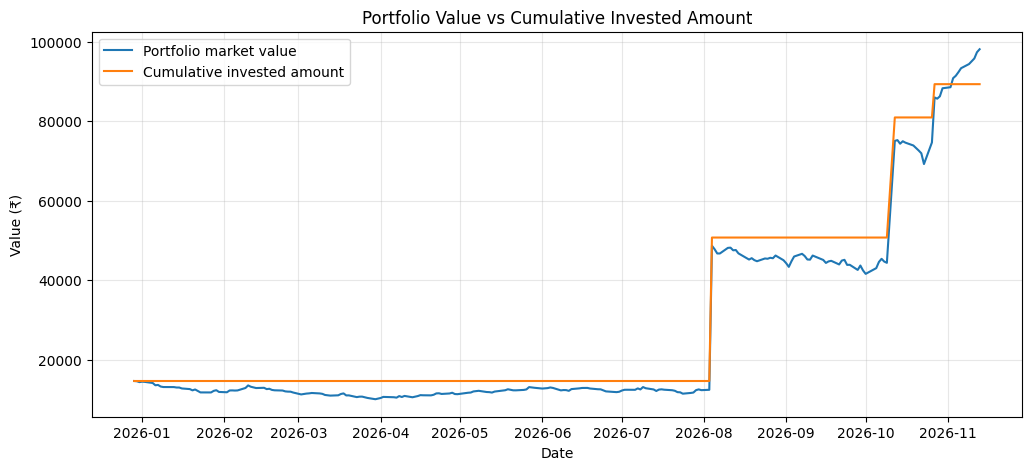

,Portfolio Value,Cumulative Invested Amount
Date,,
2026-11-06,"93,332.35","89,314.00"
2026-11-09,"94,374.75","89,314.00"
2026-11-11,"95,777.50","89,314.00"
2026-11-12,"97,351.00","89,314.00"
2026-11-13,"98,106.50","89,314.00"


In [44]:
# Add each purchase's quantity from its matched trading date onward.
daily_quantities = pd.DataFrame(0.0, index=prices.index, columns=valid_tickers)

for _, row in transactions.iterrows():
    ticker = row["ticker"]
    purchase_day = pd.Timestamp(row["price_date"])
    daily_quantities.loc[daily_quantities.index >= purchase_day, ticker] += row["quantity"]

daily_values_by_stock = prices[valid_tickers] * daily_quantities
daily_portfolio_value = daily_values_by_stock.sum(axis=1)

daily_costs = (
    transactions.groupby("price_date")["purchase_cost"]
    .sum()
    .reindex(prices.index, fill_value=0)
)
cumulative_investment = daily_costs.cumsum()

history = pd.DataFrame({
    "Portfolio Value": daily_portfolio_value,
    "Cumulative Invested Amount": cumulative_investment
})

plt.figure(figsize=(12, 5))
plt.plot(history.index, history["Portfolio Value"], label="Portfolio market value")
plt.plot(history.index, history["Cumulative Invested Amount"], label="Cumulative invested amount")
plt.title("Portfolio Value vs Cumulative Invested Amount")
plt.xlabel("Date")
plt.ylabel("Value (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
display(history.tail())

## 9. Benchmark comparison — NIFTY 50

This comparison assumes that each amount you contributed to your portfolio was instead invested in the benchmark on the same purchase date. Benchmark units are calculated using the first available benchmark closing price on or after each purchase date.

This handles staggered purchases more fairly than comparing two price charts from a single starting date. The benchmark is a hypothetical investment and does not include index-fund fees, tracking error, taxes, or transaction costs.

,Metric,Your Portfolio,^NSEI
0,Contributions invested,"₹89,314.00","₹89,314.00"
1,Value on comparison date,"₹98,106.50","₹94,280.31"
2,Profit / Loss,"₹8,792.50","₹4,966.31"
3,Simple return,9.84%,5.56%


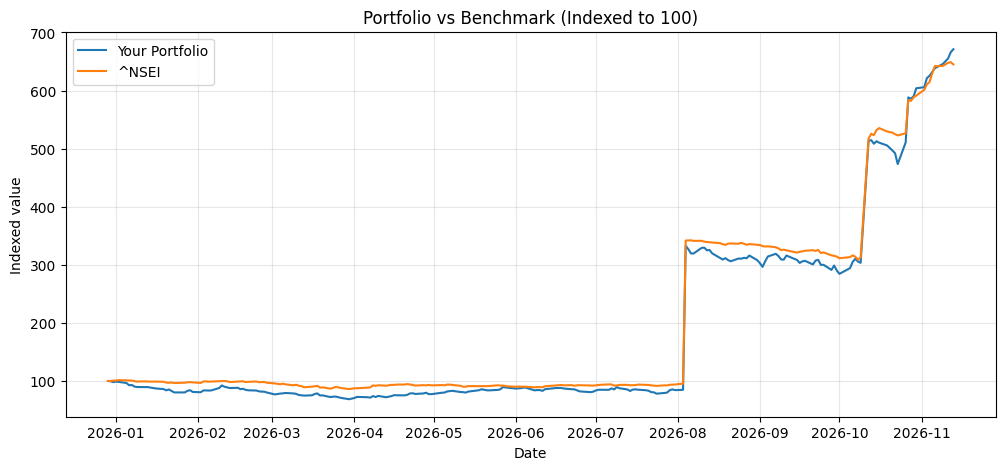

,purchase_date,benchmark_buy_date,contribution,benchmark_buy_price,benchmark_units
0,2026-10-12,2026-10-12,"30,220.00","22,363.35",1.35
1,2026-08-04,2026-08-04,"36,100.00","24,614.90",1.47
2,2025-12-29,2025-12-29,"2,775.00","25,942.10",0.11
3,2025-12-29,2025-12-29,"11,844.00","25,942.10",0.46
4,2026-10-27,2026-10-27,"8,375.00","22,749.75",0.37


In [45]:
# Download benchmark history from the earliest purchase date.
benchmark_raw = yf.download(
    benchmark_ticker,
    start=start_date,
    auto_adjust=True,
    progress=False
)

benchmark_comparison_available = False

if benchmark_raw.empty:
    print(f"Could not download benchmark data for {benchmark_ticker}.")
else:
    if isinstance(benchmark_raw.columns, pd.MultiIndex):
        if "Close" in benchmark_raw.columns.get_level_values(0):
            benchmark_prices = benchmark_raw["Close"]
        else:
            benchmark_prices = benchmark_raw.xs("Close", axis=1, level=-1)
        if isinstance(benchmark_prices, pd.DataFrame):
            benchmark_prices = benchmark_prices.iloc[:, 0]
    else:
        benchmark_prices = benchmark_raw["Close"]

    benchmark_prices = benchmark_prices.dropna()
    benchmark_prices.index = pd.to_datetime(benchmark_prices.index).tz_localize(None)
    benchmark_prices = benchmark_prices.sort_index()

    # Simulate investing each portfolio contribution in the benchmark.
    benchmark_lots = []
    for _, row in transactions.iterrows():
        eligible = benchmark_prices.loc[
            benchmark_prices.index.normalize() >= row["purchase_date"].normalize()
        ]
        if eligible.empty:
            continue

        benchmark_buy_date = eligible.index[0]
        benchmark_buy_price = float(eligible.iloc[0])
        contribution = float(row["purchase_cost"])

        benchmark_lots.append({
            "purchase_date": row["purchase_date"],
            "benchmark_buy_date": benchmark_buy_date,
            "contribution": contribution,
            "benchmark_buy_price": benchmark_buy_price,
            "benchmark_units": contribution / benchmark_buy_price
        })

    benchmark_lots = pd.DataFrame(benchmark_lots)

    if benchmark_lots.empty:
        print("Could not match purchase dates to benchmark trading dates.")
    else:
        # Use the latest common date for the comparison.
        common_date = min(pd.Timestamp(latest_date), pd.Timestamp(benchmark_prices.index[-1]))
        portfolio_value_on_common_date = float(daily_portfolio_value.loc[:common_date].iloc[-1])
        benchmark_price_on_common_date = float(benchmark_prices.loc[:common_date].iloc[-1])

        lots_as_of_common_date = benchmark_lots[
            benchmark_lots["benchmark_buy_date"] <= common_date
        ]
        benchmark_units_on_common_date = lots_as_of_common_date["benchmark_units"].sum()
        benchmark_value_on_common_date = (
            benchmark_units_on_common_date * benchmark_price_on_common_date
        )
        contributions_on_common_date = lots_as_of_common_date["contribution"].sum()

        comparison = pd.DataFrame({
            "Metric": ["Contributions invested", "Value on comparison date", "Profit / Loss", "Simple return"],
            "Your Portfolio": [
                total_invested,
                portfolio_value_on_common_date,
                portfolio_value_on_common_date - total_invested,
                portfolio_value_on_common_date / total_invested - 1
            ],
            benchmark_ticker: [
                contributions_on_common_date,
                benchmark_value_on_common_date,
                benchmark_value_on_common_date - contributions_on_common_date,
                benchmark_value_on_common_date / contributions_on_common_date - 1
            ]
        })

        # Format each metric according to its meaning.
        display_table = comparison.copy()
        for col in ["Your Portfolio", benchmark_ticker]:
            display_table[col] = [
                f"₹{v:,.2f}" if metric != "Simple return" else f"{v:.2%}"
                for metric, v in zip(comparison["Metric"], comparison[col])
            ]
        display(display_table)

        # Build benchmark's historical value using the same dated contributions.
        benchmark_daily_units = pd.Series(0.0, index=benchmark_prices.index)
        for _, lot in benchmark_lots.iterrows():
            benchmark_daily_units.loc[
                benchmark_daily_units.index >= lot["benchmark_buy_date"]
            ] += lot["benchmark_units"]

        benchmark_history = benchmark_daily_units * benchmark_prices
        combined = pd.concat([
            daily_portfolio_value.rename("Your Portfolio"),
            benchmark_history.rename(benchmark_ticker)
        ], axis=1).dropna()

        # Plot both value series on a common normalized base.
        if not combined.empty:
            normalized = combined / combined.iloc[0] * 100
            plt.figure(figsize=(12, 5))
            plt.plot(normalized.index, normalized["Your Portfolio"], label="Your Portfolio")
            plt.plot(normalized.index, normalized[benchmark_ticker], label=benchmark_ticker)
            plt.title("Portfolio vs Benchmark (Indexed to 100)")
            plt.xlabel("Date")
            plt.ylabel("Indexed value")
            plt.legend()
            plt.grid(alpha=0.3)
            plt.show()

        benchmark_comparison_available = True
        display(benchmark_lots)

## 10. Money-weighted return (XIRR)

XIRR calculates an annualized return while accounting for the **amount and date** of each cash flow. Every purchase is a negative cash flow on its entered purchase date. The latest portfolio market value is a positive terminal cash flow on the valuation date.

This is especially useful when you invest different amounts at different times. It differs from simple total return because it accounts for the timing of contributions.

In [46]:
from scipy.optimize import brentq

def calculate_xirr(cash_flows):
    """Calculate annualized XIRR from a DataFrame with date and amount columns."""
    flows = cash_flows.copy()
    flows["date"] = pd.to_datetime(flows["date"])
    flows = flows.groupby("date", as_index=False)["amount"].sum().sort_values("date")

    if not ((flows["amount"] < 0).any() and (flows["amount"] > 0).any()):
        return np.nan

    start = flows["date"].iloc[0]
    years = (flows["date"] - start).dt.days.to_numpy() / 365.0
    amounts = flows["amount"].to_numpy(dtype=float)

    def npv(rate):
        return np.sum(amounts / (1 + rate) ** years)

    # Find a rate interval where NPV changes sign.
    rates = np.concatenate([
        np.linspace(-0.9999, -0.5, 300),
        np.linspace(-0.5, 1.0, 500),
        np.geomspace(2.0, 1000.0, 300)
    ])
    previous_rate = rates[0]
    previous_npv = npv(previous_rate)

    for rate in rates[1:]:
        current_npv = npv(rate)
        if np.isfinite(previous_npv) and np.isfinite(current_npv):
            if current_npv == 0:
                return float(rate)
            if previous_npv * current_npv < 0:
                return float(brentq(npv, previous_rate, rate, maxiter=1000))
        previous_rate, previous_npv = rate, current_npv

    return np.nan

# Portfolio cash flows: purchases are outflows; current market value is the terminal inflow.
portfolio_cash_flows = pd.DataFrame({
    "date": transactions["purchase_date"],
    "amount": -transactions["purchase_cost"]
})
portfolio_cash_flows = pd.concat([
    portfolio_cash_flows,
    pd.DataFrame({"date": [latest_date], "amount": [total_value]})
], ignore_index=True)

portfolio_xirr = calculate_xirr(portfolio_cash_flows)
print(
    "Your portfolio XIRR:",
    f"{portfolio_xirr:.2%}" if pd.notna(portfolio_xirr) else "Could not calculate"
)

# Benchmark XIRR: same contribution amounts and dates, benchmark value at common date.
if benchmark_comparison_available:
    benchmark_cash_flows = pd.DataFrame({
        "date": benchmark_lots["purchase_date"],
        "amount": -benchmark_lots["contribution"]
    })
    benchmark_cash_flows = pd.concat([
        benchmark_cash_flows,
        pd.DataFrame({
            "date": [common_date],
            "amount": [benchmark_value_on_common_date]
        })
    ], ignore_index=True)

    benchmark_xirr = calculate_xirr(benchmark_cash_flows)
    print(
        f"{benchmark_ticker} XIRR:",
        f"{benchmark_xirr:.2%}" if pd.notna(benchmark_xirr) else "Could not calculate"
    )

    xirr_table = pd.DataFrame({
        "Investment": ["Your Portfolio", benchmark_ticker],
        "XIRR": [portfolio_xirr, benchmark_xirr]
    })
    display(xirr_table.style.format({"XIRR": "{:.2%}"}))

Your portfolio XIRR: 36.59%
^NSEI XIRR: 20.06%


,Investment,XIRR
0,Your Portfolio,36.59%
1,^NSEI,20.06%


## 11. Export CSV reports

In [48]:
transactions.to_csv("portfolio_purchase_ledger.csv", index=False)
holdings.to_csv("portfolio_current_holdings.csv")
history.to_csv("portfolio_daily_history.csv")
print("Created three CSV files.")
from google.colab import files
files.download("portfolio_purchase_ledger.csv")
files.download("portfolio_current_holdings.csv")
files.download("portfolio_daily_history.csv")

Created three CSV files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Interpretation

- **Quantity:** number of shares purchased.
- **Purchase date:** date you entered; mapped to the next available trading session to estimate a price.
- **Invested amount:** quantity × your entered purchase price, summed across purchase lots.
- **Current value:** total quantity held × latest available adjusted close.
- **Unrealized P&L:** current value minus estimated invested amount.

This is currently a buy-only tracker.